# include_SOCOL_HS — GeoMIP + SOCOL global & regional uncertainty

Python port of `include_SOCOL_HS.m`. Combines the 6-model GeoMIP ensemble
(`tas`, `pr`) with the SOCOL single-model aerosol-variant ensemble to compute
global-mean and IPCC-region time series of the G6sulfur / G6solar / SSP5-8.5
responses (relative to SSP2-4.5), and decomposes the end-of-century regional
uncertainty into aerosol-type, inter-model aerosol, and climate-response
contributions.

Faithful 1:1 translation of the MATLAB analysis; only the plotting back-end
(matplotlib) and the colour/utility helpers differ. The GeoMIP and SOCOL
datasets are *created by scripts in this folder*, so they are read from the
Python-native `data_py/*.npz`.

The per-region area-weighted means are **vectorised** (`field[mask, :]`)
instead of the MATLAB per-year inner loop — numerically identical, far faster.

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, brighten, movmean, shaperead, inpolygon

## Load data

In [2]:
mt = mu.load_npz("GeoMIP_tas"); x_e_tas = mt["x_e"]; LAT = mt["LAT"]; LON = mt["LON"]
mp = mu.load_npz("GeoMIP_pr"); x_e_pr = mp["x_e"]
S = mu.load_npz("data_all_SOCOL")
ta_g6_y = S["ta_g6_y"]; pr_g6_y = S["pr_g6_y"]
ta_ssp5_y = S["ta_ssp5_y"]; pr_ssp5_y = S["pr_ssp5_y"]
ta_ssp2_y = S["ta_ssp2_y"]; pr_ssp2_y = S["pr_ssp2_y"]
lat_SOCOL = S["lat_SOCOL"].ravel(); lon_SOCOL = S["lon_SOCOL"].ravel()


def region_mean_ts(field3d, mask, wS):
    """Area-weighted regional mean per year: sum(field[mask])/wS over (lon,lat)."""
    return np.nansum(field3d[mask, :], axis=0) / wS

## Global means — GeoMIP (cosine-weighted), trimming 86-year records to 81

In [3]:
x_e_gm_tas = np.full((6, 4, 81, 3), np.nan)
x_e_gm_pr = np.full((6, 4, 81, 3), np.nan)
for im in range(6):
    lat = LAT[0, im].ravel(); ww = np.cos(lat / 180 * np.pi)
    for ie in range(4):
        for inn in range(3):
            ft = x_e_tas[im, ie, inn]
            if np.size(ft) > 0 and ft.shape[0] > 0:
                zt = np.mean(ft, axis=0); zp = np.mean(x_e_pr[im, ie, inn], axis=0)
                yt = np.sum(zt * ww[:, None], axis=0) / np.sum(ww)
                yp = np.sum(zp * ww[:, None], axis=0) / np.sum(ww)
                if yt.shape[0] == 86:
                    x_e_gm_tas[im, ie, 0:81, inn] = yt[5:86]
                    x_e_gm_pr[im, ie, 0:81, inn] = yp[5:86]
                else:
                    x_e_gm_tas[im, ie, :, inn] = yt
                    x_e_gm_pr[im, ie, :, inn] = yp

## Regional means — GeoMIP (G6sulfur, G6solar, SSP5-8.5, each − SSP2-4.5)

In [4]:
regions = shaperead("IPCC-WGI-reference-regions-v4.shx")
sizeR = len(regions)

ta_reg_sulf = np.full((6, 81, sizeR), np.nan)
ta_reg_solar = np.full((6, 81, sizeR), np.nan)
ta_reg_ssp = np.full((6, 81, sizeR), np.nan)
pr_reg_sulf = np.full((6, 81, sizeR), np.nan)
pr_reg_solar = np.full((6, 81, sizeR), np.nan)
pr_reg_ssp = np.full((6, 81, sizeR), np.nan)

for im in range(6):
    lat = LAT[0, im].ravel(); lon = LON[0, im].ravel()
    ww = np.cos(lat / 180 * np.pi)
    latM, lonM = np.meshgrid(lat, lon - 180)
    AA = np.meshgrid(ww, lon)[0]
    ta1 = (x_e_tas[im, 0, 0][:, :, 0:81] - x_e_tas[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    ta2 = (x_e_tas[im, 1, 0][:, :, 0:81] - x_e_tas[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    ta3 = (x_e_tas[im, 2, 0][:, :, 0:81] - x_e_tas[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    pa1 = (x_e_pr[im, 0, 0][:, :, 0:81] - x_e_pr[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    pa2 = (x_e_pr[im, 1, 0][:, :, 0:81] - x_e_pr[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    pa3 = (x_e_pr[im, 2, 0][:, :, 0:81] - x_e_pr[im, 3, 0][:, :, 0:81]) * AA[:, :, None]
    for i in range(sizeR):
        ind = inpolygon(latM, lonM, regions[i].Y, regions[i].X)
        wS = np.sum(AA[ind])
        ta_reg_sulf[im, :, i] = region_mean_ts(ta1, ind, wS)
        ta_reg_solar[im, :, i] = region_mean_ts(ta2, ind, wS)
        ta_reg_ssp[im, :, i] = region_mean_ts(ta3, ind, wS)
        pr_reg_sulf[im, :, i] = region_mean_ts(pa1, ind, wS)
        pr_reg_solar[im, :, i] = region_mean_ts(pa2, ind, wS)
        pr_reg_ssp[im, :, i] = region_mean_ts(pa3, ind, wS)
    print("GeoMIP model", im + 1, "done")

GeoMIP model 1 done


GeoMIP model 2 done


GeoMIP model 3 done


GeoMIP model 4 done


GeoMIP model 5 done


GeoMIP model 6 done


## Global means — SOCOL (4 aerosol variants; G6, SSP5-8.5, SSP2-4.5)

In [5]:
wwS = np.cos(lat_SOCOL / 180 * np.pi)
latMS, lonMS = np.meshgrid(lat_SOCOL, lon_SOCOL - 180)
AAS = np.meshgrid(wwS, lon_SOCOL)[0]

x_e_gm_tasS = np.full((4, 4, 70, 3), np.nan)
x_e_gm_prS = np.full((4, 4, 70, 3), np.nan)
for ie in range(4):
    for inn in range(3):
        def gm(field):
            zm = np.mean(field, axis=0)                      # (lat, year)
            return np.sum(zm * wwS[:, None], axis=0) / np.sum(wwS)
        x_e_gm_tasS[ie, 0, :, inn] = gm(ta_g6_y[:, :, :, inn, ie])
        x_e_gm_prS[ie, 0, :, inn] = gm(pr_g6_y[:, :, :, inn, ie] * 86400)
        x_e_gm_tasS[ie, 2, :, inn] = gm(ta_ssp5_y[:, :, :, inn])
        x_e_gm_prS[ie, 2, :, inn] = gm(pr_ssp5_y[:, :, :, inn] * 86400)
        x_e_gm_tasS[ie, 3, :, inn] = gm(ta_ssp2_y[:, :, :, inn])
        x_e_gm_prS[ie, 3, :, inn] = gm(pr_ssp2_y[:, :, :, inn] * 86400)

## Regional means — SOCOL

In [6]:
ta_reg_sulfS = np.full((4, 70, 3, sizeR), np.nan)
ta_reg_sspS = np.full((4, 70, 3, sizeR), np.nan)
pr_reg_sulfS = np.full((4, 70, 3, sizeR), np.nan)
pr_reg_sspS = np.full((4, 70, 3, sizeR), np.nan)

# precompute region masks / weights once on the SOCOL grid
masks = []; wSs = np.empty(sizeR)
for i in range(sizeR):
    ind = inpolygon(latMS, lonMS, regions[i].Y, regions[i].X)
    masks.append(ind); wSs[i] = np.sum(AAS[ind])

for ie in range(4):
    for inn in range(3):
        ta1S = (ta_g6_y[:, :, :, inn, ie] - ta_ssp2_y[:, :, :, inn]) * AAS[:, :, None]
        ta3S = (ta_ssp5_y[:, :, :, inn] - ta_ssp2_y[:, :, :, inn]) * AAS[:, :, None]
        pa1S = (pr_g6_y[:, :, :, inn, ie] - pr_ssp2_y[:, :, :, inn]) * AAS[:, :, None]
        pa3S = (pr_ssp5_y[:, :, :, inn] - pr_ssp2_y[:, :, :, inn]) * AAS[:, :, None]
        for i in range(sizeR):
            ind = masks[i]; wS = wSs[i]
            ta_reg_sulfS[ie, :, inn, i] = region_mean_ts(ta1S, ind, wS)
            ta_reg_sspS[ie, :, inn, i] = region_mean_ts(ta3S, ind, wS)
            pr_reg_sulfS[ie, :, inn, i] = region_mean_ts(pa1S * 86400, ind, wS)
            pr_reg_sspS[ie, :, inn, i] = region_mean_ts(pa3S * 86400, ind, wS)
    print("SOCOL variant", ie + 1, "done")

SOCOL variant 1 done
SOCOL variant 2 done


SOCOL variant 3 done
SOCOL variant 4 done


## Global time series (tas and pr)
Per-model thin lines (Pastel1), multi-model means (darker), grand mean
(darkest), with the SOCOL ensemble overlaid on 2031–2100.

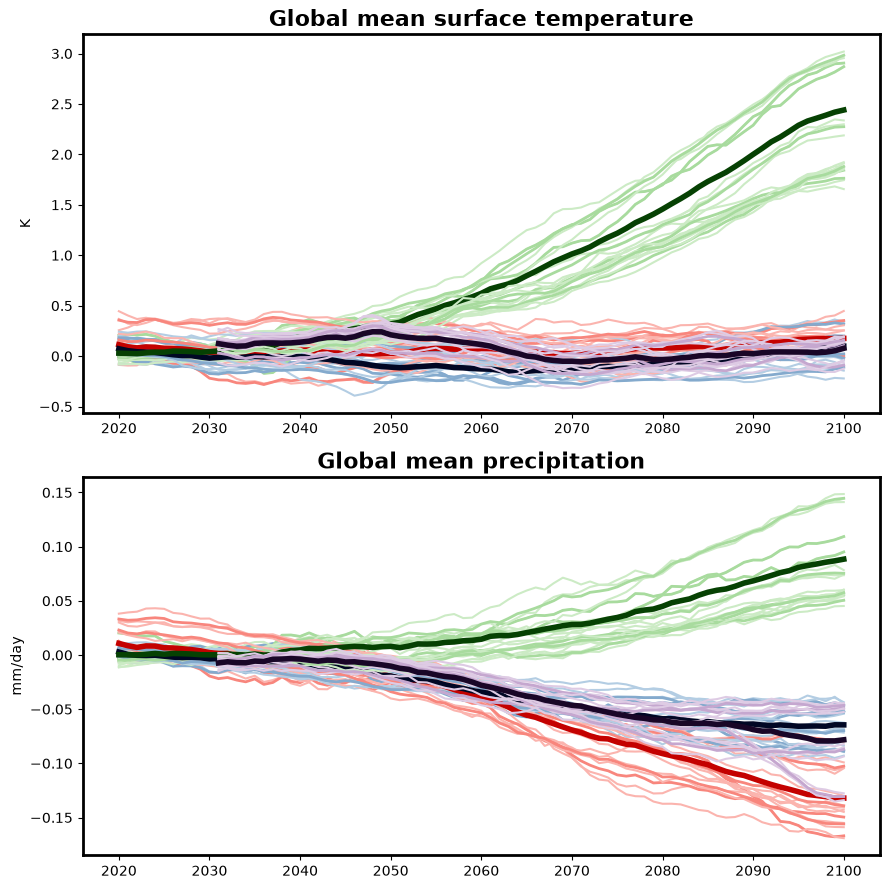

In [7]:
time = np.arange(2020, 2101)
time2 = np.arange(2031, 2101)
mvm = 10
fc = brewermap(5, "Pastel1"); fc2 = brighten(fc, -0.3); fc3 = brighten(fc2, -0.8)


def global_panel(ax, gm, gmS, ylabel, title):
    sulf = np.full((6, 81), np.nan); sola = np.full((6, 81), np.nan); ssp = np.full((6, 81), np.nan)
    for im in range(6):
        for inn in range(3):
            ax.plot(time, movmean(gm[im, 0, :, inn] - gm[im, 3, :, inn], mvm), color=fc[0])
            ax.plot(time, movmean(gm[im, 1, :, inn] - gm[im, 3, :, inn], mvm), color=fc[1])
            ax.plot(time, movmean(gm[im, 2, :, inn] - gm[im, 3, :, inn], mvm), color=fc[2])
        x = np.nanmean(gm[im, 0], axis=1) - np.nanmean(gm[im, 3], axis=1)
        y = np.nanmean(gm[im, 1], axis=1) - np.nanmean(gm[im, 3], axis=1)
        z = np.nanmean(gm[im, 2], axis=1) - np.nanmean(gm[im, 3], axis=1)
        ax.plot(time, movmean(x, mvm), color=fc2[0], linewidth=2)
        ax.plot(time, movmean(y, mvm), color=fc2[1], linewidth=2)
        ax.plot(time, movmean(z, mvm), color=fc2[2], linewidth=2)
        sulf[im] = x; sola[im] = y; ssp[im] = z
    ax.plot(time, movmean(np.mean(sulf, 0), mvm), color=fc3[0], linewidth=4)
    ax.plot(time, movmean(np.mean(sola, 0), mvm), color=fc3[1], linewidth=4)
    ax.plot(time, movmean(np.mean(ssp, 0), mvm), color=fc3[2], linewidth=4)
    sulfS = np.full((4, 70), np.nan); sspS = np.full((4, 70), np.nan)
    for im in range(4):
        for inn in range(3):
            ax.plot(time2, movmean(gmS[im, 0, :, inn] - gmS[im, 3, :, inn], mvm), color=fc[3])
            if im == 0:
                ax.plot(time2, movmean(gmS[im, 2, :, inn] - gmS[im, 3, :, inn], mvm), color=fc[2])
        x = np.nanmean(gmS[im, 0], axis=1) - np.nanmean(gmS[im, 3], axis=1)
        z = np.nanmean(gmS[im, 2], axis=1) - np.nanmean(gmS[im, 3], axis=1)
        ax.plot(time2, movmean(x, mvm), color=fc2[3], linewidth=2)
        if im == 0:
            ax.plot(time2, movmean(z, mvm), color=fc2[2], linewidth=2)
        sulfS[im] = x; sspS[im] = z
    ax.plot(time2, movmean(np.mean(sulfS, 0), mvm), color=fc3[3], linewidth=4)
    ax.set_title(title, fontsize=16, fontweight="bold"); ax.set_ylabel(ylabel)
    for s in ax.spines.values():
        s.set_linewidth(2)


fig1, (axa, axb) = plt.subplots(2, 1, figsize=(9, 9))
global_panel(axa, x_e_gm_tas, x_e_gm_tasS, "K", "Global mean surface temperature")
global_panel(axb, x_e_gm_pr, x_e_gm_prS, "mm/day", "Global mean precipitation")
fig1.tight_layout(); plt.show()

## End-of-century regional variance partition
For each region: GeoMIP inter-model variance of the 2080–2100 mean for
G6sulfur / G6solar / SSP5-8.5, and the SOCOL aerosol-type variance
(2089–2099 mean across the 4 variants). All sample variances (`ddof=1`).

In [8]:
ta_var_sulf = np.array([np.std(np.mean(ta_reg_sulf[:, 60:81, i], 1), ddof=1) ** 2 for i in range(sizeR)])
ta_var_solar = np.array([np.std(np.mean(ta_reg_solar[:, 60:81, i], 1), ddof=1) ** 2 for i in range(sizeR)])
ta_var_ssp = np.array([np.std(np.mean(ta_reg_ssp[:, 60:81, i], 1), ddof=1) ** 2 for i in range(sizeR)])
ta_var_sulfS = np.array([np.std(np.mean(np.mean(ta_reg_sulfS[:, 49:70, :, i], 1), 1), ddof=1) ** 2 for i in range(sizeR)])

pr_var_sulf = np.array([np.std(np.mean(pr_reg_sulf[:, 60:81, i], 1), ddof=1) ** 2 for i in range(sizeR)])
pr_var_solar = np.array([np.std(np.mean(pr_reg_solar[:, 60:81, i], 1), ddof=1) ** 2 for i in range(sizeR)])
pr_var_ssp = np.array([np.std(np.mean(pr_reg_ssp[:, 60:81, i], 1), ddof=1) ** 2 for i in range(sizeR)])
pr_var_sulfS = np.array([np.std(np.mean(np.mean(pr_reg_sulfS[:, 49:70, :, i], 1), 1), ddof=1) ** 2 for i in range(sizeR)])

## Fractional-uncertainty figure (fig 99 in MATLAB): tas and pr
Layered areas: total (100%), (solar+sulf aerosol impacts), and solar-only,
with continental-group median bars. `col_regs`/`spa_regs2`/`mid_regs` are the
MATLAB 1-based index lists converted to 0-based.

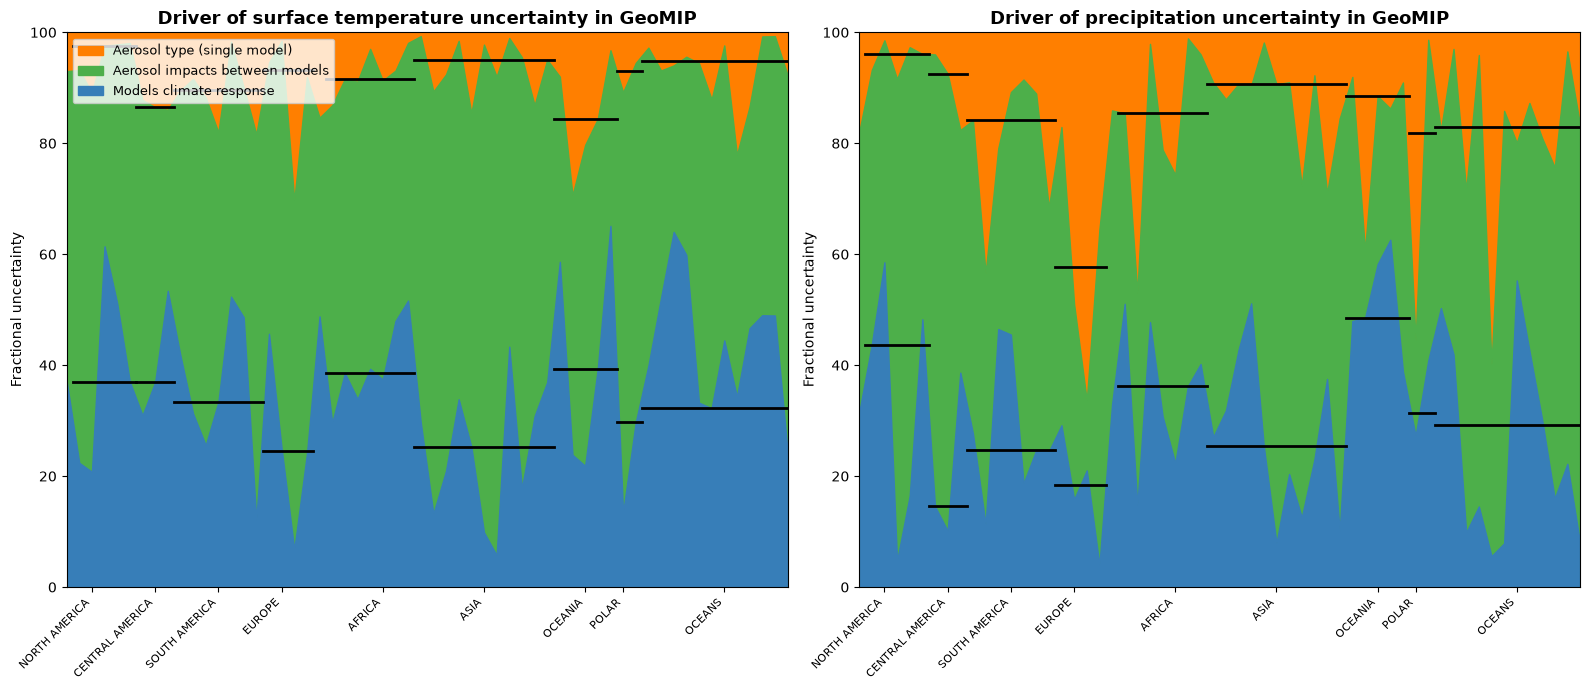

In [9]:
fcs = brewermap(5, "Set1")
col_regs = [[0, 44, 45], [1, 2, 3, 4, 5], [6, 7, 8], list(range(9, 16)),
            [16, 17, 18, 19], [21, 22, 23, 24, 25, 26, 27], list(range(28, 39)),
            [39, 40, 41, 42, 43], [46, 57]]
spa_regs2 = [[44.5, 46.5], [1.5, 6.5], [6.5, 9.5], [9.5, 16.5], [16.5, 20.5],
             [21.5, 28.5], [28.5, 39.5], [39.5, 44.5], [46.5, 58.5]]
mid_regs = [3, 8, 13, 18, 26, 34, 42, 45, 53]
mid_regN = ['NORTH AMERICA', 'CENTRAL AMERICA', 'SOUTH AMERICA', 'EUROPE',
            'AFRICA', 'ASIA', 'OCEANIA', 'POLAR', 'OCEANS']
xr = np.arange(1, sizeR + 1)


def partition_panel(ax, v_sulf, v_solar, v_sulfS, title):
    tot = v_sulf + v_solar + v_sulfS
    totsd_S = (v_solar + v_sulf) / tot * 100
    totsd_SS = (v_solar) / tot * 100
    # Label/colour mapping matches MATLAB p(1),p(2),p(3) exactly:
    #   orange (fcs5, full 100%)  -> 'Aerosol type (single model)'
    #   green  (fcs3, solar+sulf) -> 'Aerosol impacts between models'
    #   blue   (fcs2, solar)      -> 'Models climate response'
    ax.fill_between(xr, np.full(sizeR, 100.0), 0, color=fcs[4], step=None,
                    label="Aerosol type (single model)")
    ax.fill_between(xr, totsd_S, 0, color=fcs[2], label="Aerosol impacts between models")
    ax.fill_between(xr, totsd_SS, 0, color=fcs[1], label="Models climate response")
    for g in range(len(col_regs)):
        ax.plot(spa_regs2[g], [np.median(totsd_S[col_regs[g]])] * 2, "k", linewidth=2)
        ax.plot(spa_regs2[g], [np.median(totsd_SS[col_regs[g]])] * 2, "k", linewidth=2)
    ax.set_xlim(1, sizeR); ax.set_ylim(0, 100)
    # x-axis is 1..58 (xr), same coordinate as MATLAB area(1:58); the median bars
    # (spa_regs2) and labels (mid_regs) are in that coordinate — no +1 offset.
    ax.set_xticks(mid_regs); ax.set_xticklabels(mid_regN, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("Fractional uncertainty"); ax.set_title(title, fontsize=13, fontweight="bold")


fig99, (a1, a2) = plt.subplots(1, 2, figsize=(16, 7))
partition_panel(a1, ta_var_sulf, ta_var_solar, ta_var_sulfS,
                "Driver of surface temperature uncertainty in GeoMIP")
partition_panel(a2, pr_var_sulf, pr_var_solar, pr_var_sulfS,
                "Driver of precipitation uncertainty in GeoMIP")
a1.legend(loc="upper left", fontsize=9)   # labels set on the artists, MATLAB order
fig99.tight_layout(); plt.show()

## African-region time series (GeoMIP + SOCOL): T and P
The 7 African IPCC-WGI regions (22–28: Western/Central/N.Eastern/S.Eastern/
W.Southern/E.Southern Africa, Madagascar). Per region: GeoMIP per-model thin
lines (G6sulfur/G6solar/SSP5-8.5), multi-model means (thick), end-of-century
spread error bars, and the SOCOL G6sulfur ensemble (2031–2100) with its own
error bar. Reproduces the MATLAB `..._tas_Africa` / `..._pr_Africa` figures.

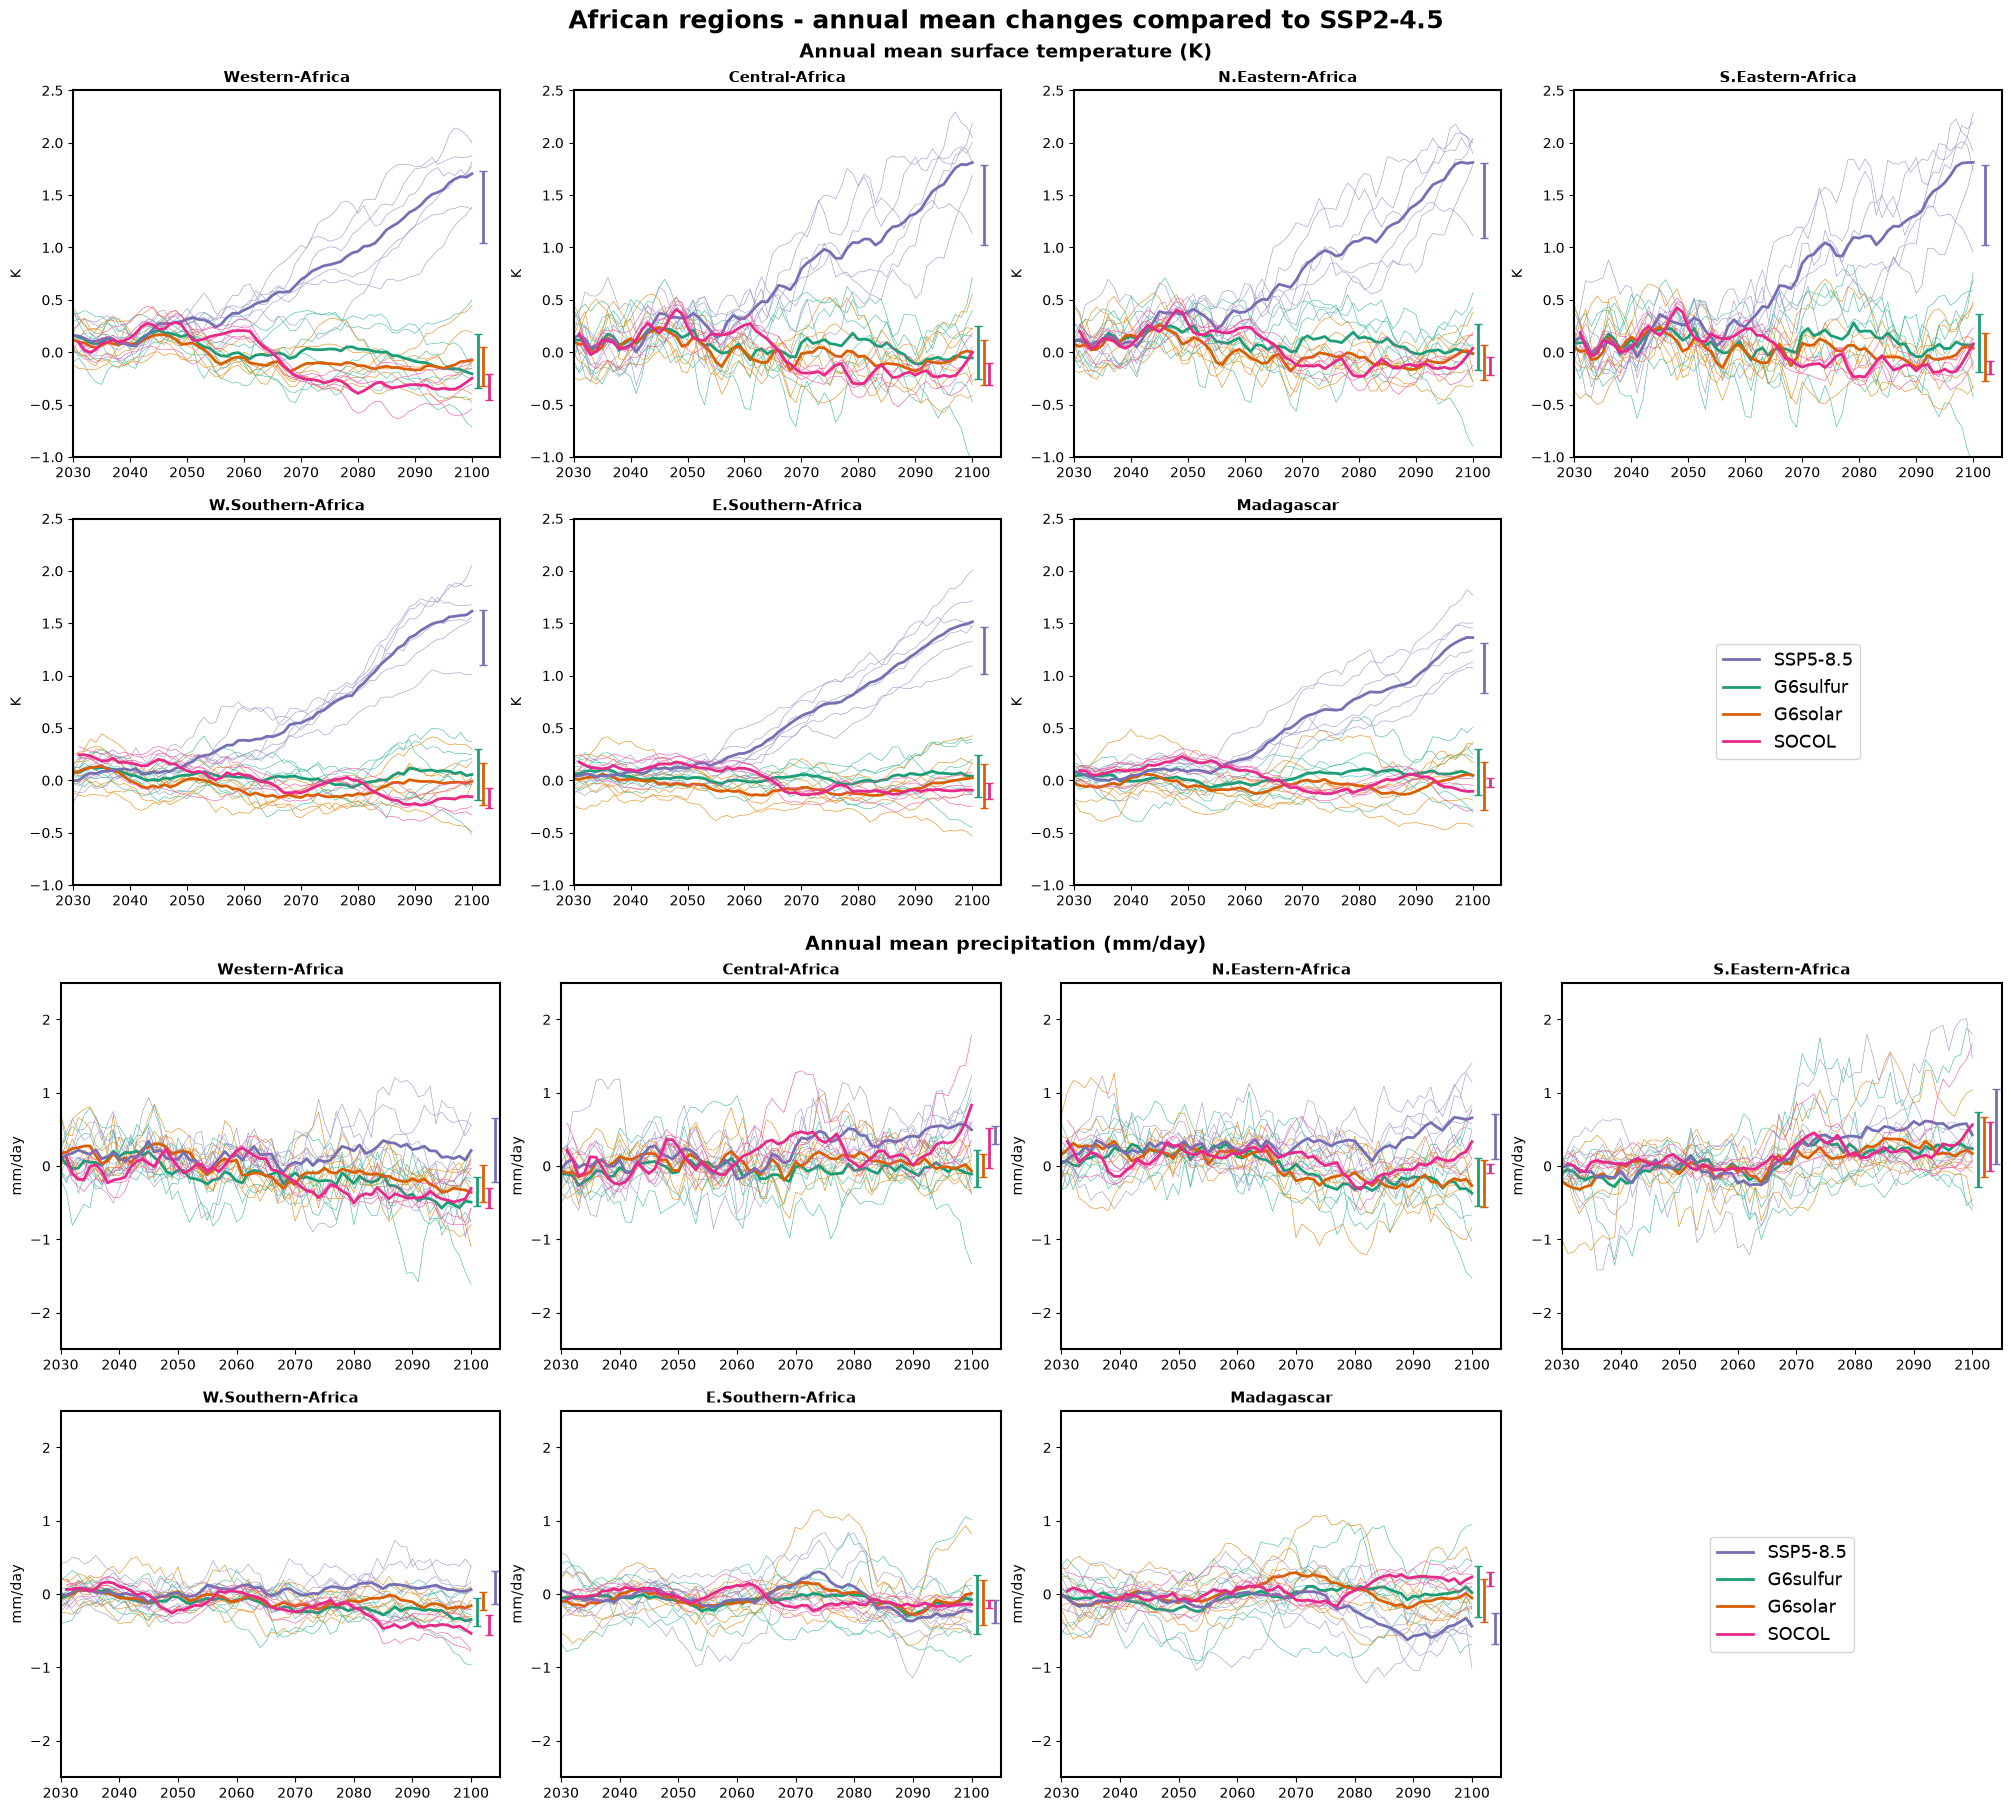

In [10]:
AFR = list(range(21, 28))    # MATLAB regions 22:28 -> 0-based


def fill_africa(axf, reg_sulf, reg_solar, reg_ssp, reg_sulfS, ylab, ylim, ssp_x):
    """Fill a block of 8 axes (7 African region panels + 1 legend slot)."""
    fcs2 = brewermap(7, "Dark2"); fcsl = brighten(fcs2, 0.2)
    handles = None
    for k, i in enumerate(AFR):
        ax = axf[k]
        for im in range(6):
            ax.plot(time, movmean(reg_sulf[im, :, i], 10), color=fcsl[0], linewidth=.4)
            ax.plot(time, movmean(reg_solar[im, :, i], 10), color=fcsl[1], linewidth=.4)
            ax.plot(time, movmean(reg_ssp[im, :, i], 10), color=fcsl[2], linewidth=.4)
        h_sulf, = ax.plot(time, movmean(reg_sulf[:, :, i].mean(0), 10), color=fcs2[0], linewidth=2)
        h_sol, = ax.plot(time, movmean(reg_solar[:, :, i].mean(0), 10), color=fcs2[1], linewidth=2)
        h_ssp, = ax.plot(time, movmean(reg_ssp[:, :, i].mean(0), 10), color=fcs2[2], linewidth=2)
        x = reg_sulf[:, 60:81, i].mean(1); y = reg_solar[:, 60:81, i].mean(1); z = reg_ssp[:, 60:81, i].mean(1)
        ax.errorbar(2101, x.mean(), yerr=np.std(x, ddof=1), color=fcs2[0], linewidth=2, capsize=3)
        ax.errorbar(2102, y.mean(), yerr=np.std(y, ddof=1), color=fcs2[1], linewidth=2, capsize=3)
        ax.errorbar(ssp_x, z.mean(), yerr=np.std(z, ddof=1), color=fcs2[2], linewidth=2, capsize=3)
        for im in range(4):
            ax.plot(time2, movmean(reg_sulfS[im, :, :, i].mean(1), 10), color=fcsl[3], linewidth=.4)
        h_soc, = ax.plot(time2, movmean(reg_sulfS[:, :, :, i].mean(2).mean(0), 10), color=fcs2[3], linewidth=2)
        kk = reg_sulfS[:, 49:70, :, i].mean(1).mean(1)
        ax.errorbar(2103, kk.mean(), yerr=np.std(kk, ddof=1), color=fcs2[3], linewidth=2, capsize=3)
        ax.set_title(regions[i].Name, fontsize=11, fontweight="bold")
        ax.set_ylabel(ylab); ax.set_xlim(2030, 2105); ax.set_ylim(*ylim)
        for s in ax.spines.values():
            s.set_linewidth(1.5)
        handles = [h_ssp, h_sulf, h_sol, h_soc]
    axf[7].axis("off")
    axf[7].legend(handles, ["SSP5-8.5", "G6sulfur", "G6solar", "SOCOL"],
                  loc="center", fontsize=13, frameon=True)


# single combined figure: temperature (top block) + precipitation (bottom block),
# using subfigures so the two blocks are cleanly separated.
fig_afr = plt.figure(figsize=(20, 18), constrained_layout=True)
sf_t, sf_p = fig_afr.subfigures(2, 1)
fill_africa(sf_t.subplots(2, 4).ravel(), ta_reg_sulf, ta_reg_solar, ta_reg_ssp, ta_reg_sulfS, "K", (-1, 2.5), 2102)
sf_t.suptitle("Annual mean surface temperature (K)", fontsize=14, fontweight="bold")
fill_africa(sf_p.subplots(2, 4).ravel(), pr_reg_sulf, pr_reg_solar, pr_reg_ssp, pr_reg_sulfS, "mm/day", (-2.5, 2.5), 2104)
sf_p.suptitle("Annual mean precipitation (mm/day)", fontsize=14, fontweight="bold")
fig_afr.suptitle("African regions - annual mean changes compared to SSP2-4.5",
                 fontsize=18, fontweight="bold")
plt.show()

Figures saved to `py_outputs/` (originals untouched).

In [11]:
import os
os.makedirs("py_outputs", exist_ok=True)
fig1.savefig("py_outputs/GeoMIP_uncertainties_aerosols_SOCOL_global.png", dpi=300, bbox_inches="tight")
fig99.savefig("py_outputs/GeoMIP_uncertainties_aerosols_SOCOL_tas_pr.png", dpi=300, bbox_inches="tight")
fig_afr.savefig("py_outputs/Africa_SOCOL.png", dpi=300, bbox_inches="tight")
print("done; region count:", sizeR)

done; region count: 58
